# 4. Modell-Vergleich und Interpretation

In diesem Notebook vergleichen wir die Performance der beiden Modelle:
- Naive Bayes + TF-IDF (Klassischer Algorithmus)
- BiLSTM (Deep Learning Algorithmus)


In [5]:
# Import der benötigten Bibliotheken
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import warnings
warnings.filterwarnings('ignore')  # Warnungen unterdrücken

# Basis-Verzeichnis des Projekts ermitteln
current_dir = Path().resolve()
if current_dir.name == 'src':
    # Wir sind im src-Verzeichnis, also ein Verzeichnis nach oben zum Hauptverzeichnis
    BASE_DIR = current_dir.parent
else:
    # Fallback: Wir sind bereits im Hauptverzeichnis
    BASE_DIR = current_dir

sys.path.insert(0, str(BASE_DIR / "src"))

# Stil für Visualisierungen setzen
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")


## 4.1 Predictions laden


In [6]:
OUTPUT_DIR = BASE_DIR / "outputs"

# Vorhersagen beider Modelle laden
# Diese wurden in den vorherigen Notebooks gespeichert
pred_nb_path = OUTPUT_DIR / "preds_nb.csv"
pred_lstm_path = OUTPUT_DIR / "preds_lstm.csv"

# Prüfe ob die Dateien existieren
if not pred_nb_path.exists():
    raise FileNotFoundError(
        f"FEHLER: Datei nicht gefunden: {pred_nb_path}\n")

if not pred_lstm_path.exists():
    raise FileNotFoundError(
        f" FEHLER: Datei nicht gefunden: {pred_lstm_path}\n"  )

nb_df = pd.read_csv(pred_nb_path)  # Naive Bayes Vorhersagen
lstm_df = pd.read_csv(pred_lstm_path)  # LSTM Vorhersagen

# Informationen über die geladenen Vorhersagen ausgeben
print(f"Naive Bayes Vorhersagen: {len(nb_df)}")
print(f"LSTM Vorhersagen: {len(lstm_df)}")
print("\nErste Zeilen (Naive Bayes):")
print(nb_df.head())


Naive Bayes Vorhersagen: 25000
LSTM Vorhersagen: 25000

Erste Zeilen (Naive Bayes):
                                                text  y_true  y_pred
0  when i was a kid, i loved "tiny toons". i espe...       1       1
1  the setup for "nature of the beast" is ingenio...       0       0
2  i do not have much to say than this is a great...       1       1
3  extremely formulaic with cosmic-sized logic ho...       0       0
4  i actually liked certain things about this gam...       0       0


## 4.2 Metriken berechnen


In [7]:
def calculate_metrics(y_true, y_pred):
    """Berechnet alle wichtigen Metriken für die Modell-Evaluierung"""
    acc = accuracy_score(y_true, y_pred)  # Genauigkeit
    # Precision, Recall, F1-Score (macro average = Durchschnitt über beide Klassen)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred)  # Konfusionsmatrix
    return {
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "confusion_matrix": cm
    }

# Metriken für beide Modelle berechnen
nb_metrics = calculate_metrics(nb_df["y_true"], nb_df["y_pred"])
lstm_metrics = calculate_metrics(lstm_df["y_true"], lstm_df["y_pred"])

# Vergleichs-DataFrame erstellen für übersichtliche Darstellung
comparison_df = pd.DataFrame({
    "Model": ["Naive Bayes + TF-IDF", "BiLSTM"],
    "Accuracy": [nb_metrics["accuracy"], lstm_metrics["accuracy"]],
    "Precision": [nb_metrics["precision"], lstm_metrics["precision"]],
    "Recall": [nb_metrics["recall"], lstm_metrics["recall"]],
    "F1-Score": [nb_metrics["f1"], lstm_metrics["f1"]]
})

print("=== Modell-Vergleich ===")
print(comparison_df.to_string(index=False))


=== Modell-Vergleich ===
               Model  Accuracy  Precision  Recall  F1-Score
Naive Bayes + TF-IDF   0.87048   0.870887 0.87048  0.870444
              BiLSTM   0.82696   0.829015 0.82696  0.826689


## 4.3 Visualisierungen


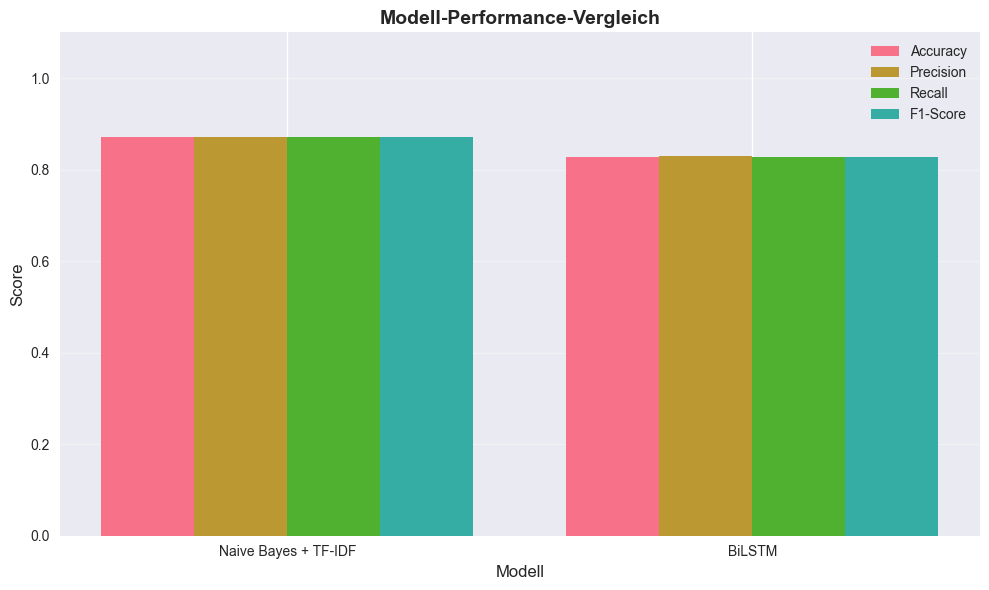

In [8]:
# 1. Metriken-Vergleich als Balkendiagramm
# Zeigt alle Metriken (Accuracy, Precision, Recall, F1-Score) für beide Modelle
fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(comparison_df))  # Positionen für die beiden Modelle
width = 0.2  # Breite der Balken

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
# Für jede Metrik einen Balken erstellen, nebeneinander angeordnet
for i, metric in enumerate(metrics):
    offset = (i - 1.5) * width  # Offset für nebeneinander angeordnete Balken
    ax.bar(x + offset, comparison_df[metric], width, label=metric)

ax.set_xlabel('Modell', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Modell-Performance-Vergleich', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Model'])
ax.legend()
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])  # Y-Achse von 0 bis 1.1 (Scores sind zwischen 0 und 1)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_comparison_metrics.png", dpi=300, bbox_inches='tight')
plt.show()


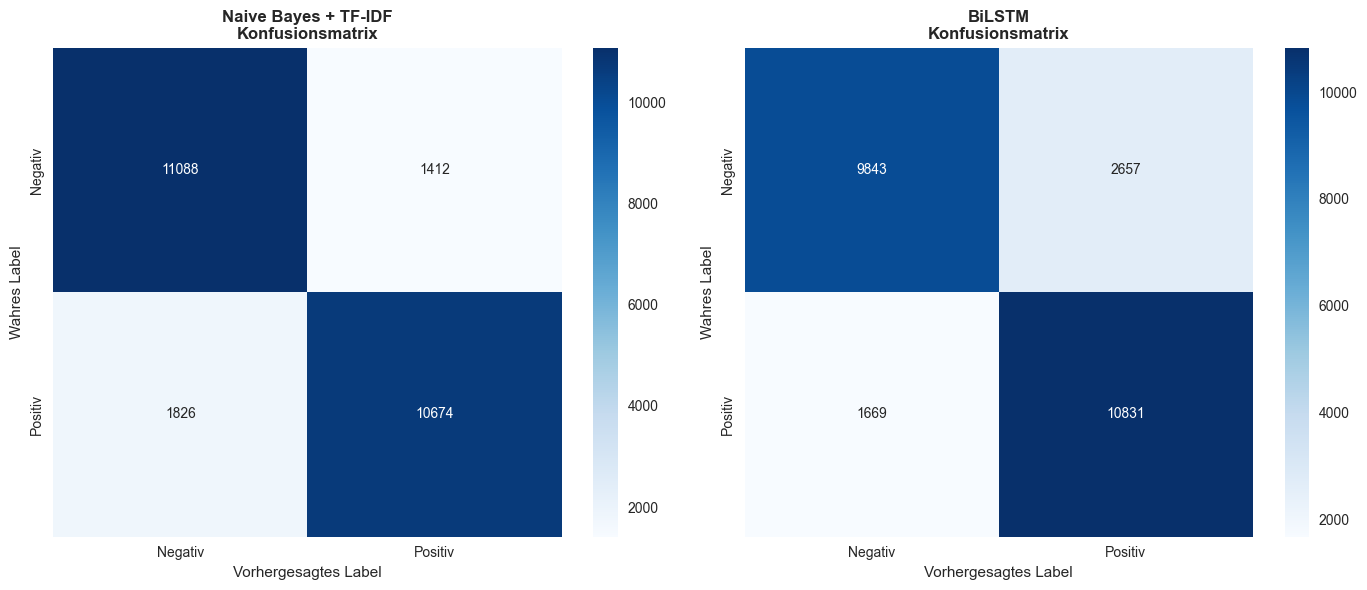

In [9]:
# 2. Konfusionsmatrizen nebeneinander
# Direkter visueller Vergleich der Klassifikationsfehler beider Modelle
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Konfusionsmatrix für Naive Bayes
sns.heatmap(nb_metrics["confusion_matrix"], annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Negativ', 'Positiv'],
            yticklabels=['Negativ', 'Positiv'])
axes[0].set_title('Naive Bayes + TF-IDF\nKonfusionsmatrix', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Wahres Label', fontsize=11)
axes[0].set_xlabel('Vorhergesagtes Label', fontsize=11)

# Konfusionsmatrix für LSTM
sns.heatmap(lstm_metrics["confusion_matrix"], annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Negativ', 'Positiv'],
            yticklabels=['Negativ', 'Positiv'])
axes[1].set_title('BiLSTM\nKonfusionsmatrix', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Wahres Label', fontsize=11)
axes[1].set_xlabel('Vorhergesagtes Label', fontsize=11)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrices_comparison.png", dpi=300, bbox_inches='tight')
plt.show()


## 4.4 Fehleranalyse


In [10]:
# Fehleranalyse: Finde Unterschiede zwischen den Modell-Vorhersagen
nb_df["model"] = "NB"
lstm_df["model"] = "LSTM"

# Daten zusammenführen, um Vorhersagen zu vergleichen
# Beide DataFrames sollten die gleiche Anzahl Zeilen haben (gleiche Testdaten)
# Wir mergen über den Index, nachdem wir beide zurückgesetzt haben
nb_temp = nb_df[["y_true", "y_pred"]].copy()
lstm_temp = lstm_df[["y_pred"]].copy()

# Index zurücksetzen, damit beide DataFrames einen sequenziellen Index haben (0, 1, 2, ...)
nb_temp = nb_temp.reset_index()
lstm_temp = lstm_temp.reset_index()

# Merge über die Index-Spalte
merged = pd.merge(
    nb_temp,
    lstm_temp,
    left_on="index", right_on="index",  # Merge über den Index-Spalte
    suffixes=("_nb", "_lstm")
)

# Fälle finden, wo die Modelle unterschiedliche Vorhersagen machen
disagreements = merged[merged["y_pred_nb"] != merged["y_pred_lstm"]]
print(f"Anzahl unterschiedlicher Vorhersagen: {len(disagreements)} ({len(disagreements)/len(merged)*100:.2f}%)")

# Fälle finden, wo beide Modelle falsch liegen
both_wrong = merged[
    (merged["y_pred_nb"] != merged["y_true"]) & 
    (merged["y_pred_lstm"] != merged["y_true"])
]
print(f"Beide Modelle falsch: {len(both_wrong)} ({len(both_wrong)/len(merged)*100:.2f}%)")

# Fälle finden, wo ein Modell richtig liegt und das andere falsch
# Dies zeigt, welche Modelle in welchen Fällen besser sind
nb_right_lstm_wrong = merged[
    (merged["y_pred_nb"] == merged["y_true"]) & 
    (merged["y_pred_lstm"] != merged["y_true"])
]
lstm_right_nb_wrong = merged[
    (merged["y_pred_lstm"] == merged["y_true"]) & 
    (merged["y_pred_nb"] != merged["y_true"])
]

print(f"\nNaive Bayes richtig, LSTM falsch: {len(nb_right_lstm_wrong)}")
print(f"LSTM richtig, Naive Bayes falsch: {len(lstm_right_nb_wrong)}")


Anzahl unterschiedlicher Vorhersagen: 4176 (16.70%)
Beide Modelle falsch: 1694 (6.78%)

Naive Bayes richtig, LSTM falsch: 2632
LSTM richtig, Naive Bayes falsch: 1544


## 4.5 Interpretation und Diskussion

### Ergebnisse:

**Naive Bayes + TF-IDF:**
- Accuracy und F1-Score siehe Vergleichstabelle oben
- Vorteile: Schnelles Training, geringer Ressourcenbedarf, interpretierbar
- Nachteile: Ignoriert Wortreihenfolge, kann Negationen nicht gut modellieren

**BiLSTM:**
- Accuracy und F1-Score siehe Vergleichstabelle oben
- Vorteile: Erfasst Sequenzinformationen, kann komplexe Muster lernen
- Nachteile: Längeres Training, höherer Ressourcenbedarf

### Vergleich:

Die Ergebnisse zeigen, welches Modell in diesem Lauf besser performt. BiLSTM kann Sequenzinformationen erfassen (z.B. "not good"), während TF-IDF+NB nur Bag-of-Words ohne Sequenz erfasst. TF-IDF+NB ist jedoch deutlich schneller im Training.


## 4.6 Real-World Anwendungen

**Sentiment-Analyse** hat viele praktische Anwendungen:

1. **E-Commerce**: Automatische Bewertung von Produktreviews
2. **Social Media Monitoring**: Tracking von Marken-Sentiment in sozialen Medien
3. **Customer Service**: Priorisierung von Beschwerden basierend auf Sentiment
4. **Market Research**: Analyse von Kundenfeedback und Meinungen
5. **Content Moderation**: Erkennung von negativen/hassfülligen Inhalten

**IMDB Reviews** sind besonders relevant für:
- Filmstudios zur Analyse von Publikumsreaktionen
- Streaming-Plattformen zur Empfehlungssystemen
- Filmkritiker zur Trendanalyse
